# 02. NV2 — Phân cụm hành vi chiếm dụng trạm sạc (Palo Alto, CA)


### Nạp dữ liệu, làm sạch và quy tắc hợp lệ


tổng số dòng dữ liệu ban đầu : 259,415
  bỏ dòng thiếu Transaction Date : 209
  phục hồi ngày dạng số (serial)  : 40
  bỏ vì lệ thời lượng/năng lượng  : 0
  -> PHIÊN HỢP LỆ                 : 259,206
     thời lượng tổng không dương      0
     thời lượng sạc không dương       0
     năng lượng thiếu hoặc âm         0

cần bội vì tổng thời lượng < thời lượng sạc (đã kẹp T_idle về 0): 45 phien (0.017%)
số phiên có T_idle = 0           : 86
số phiên vượt 24h kết nối        : 22 (0.008%)
số phiên vượt 24h sạc giờ        : 14
      Thời gian sạc (h)  Thời gian nhàn rỗi (h)  Tỷ lệ nhàn rỗi  Năng lượng (kWh)
0.00              0.002                   0.000           0.000             0.010
0.25              1.040                   0.004           0.002             3.784
0.50              1.817                   0.007           0.009             6.869
0.75              2.697                   0.355           0.151            11.459
1.00             22.932                 112.547           0.999

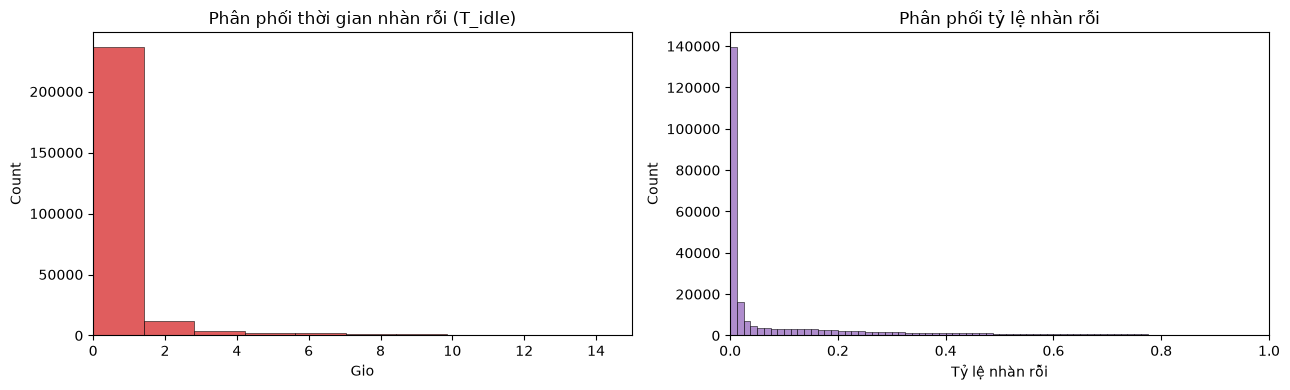

ghi chú: 75% phiên có idle_ratio dưới 0,151; trung vị chỉ 0,009 — phân bố lệch phải mạnh.


In [1]:
import numpy as np, pandas as pd, itertools, re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)

CSV = '/mnt/c/Users/bruhgundy/Downloads/EVChargingStationUsage.csv'
FEATS = ['charging_h', 'idle_h', 'kWh']          # 3 bien phan cum
RANDOM_STATE, N_INIT, N_SIL = 42, 10, 10000      # mau tinh chi so noi tai

df = pd.read_csv(CSV, low_memory=False, encoding='utf-8-sig')
N_RAW = len(df)
blank = df['Transaction Date (Pacific Time)'].isna()
N_BLANK = int(blank.sum())
df = df.loc[~blank].copy()

def to_dt(s):
    s = s.astype(str).str.strip()
    out = pd.to_datetime(s, errors='coerce')
    serial = pd.to_numeric(s, errors='coerce')
    need = out.isna() & serial.notna()
    if need.any():
        rec = pd.Timestamp('1899-12-30') + pd.to_timedelta(serial[need], unit='D')
        out = out.astype('datetime64[us]')
        out.loc[need] = rec.astype('datetime64[us]')
    return out

N_SERIAL = 0
for c in ['Start Date', 'End Date']:
    was_na = pd.to_datetime(df[c], errors='coerce').isna()
    df[c] = to_dt(df[c])
    N_SERIAL += int((was_na & df[c].notna()).sum())

df['Station Name'] = (df['Station Name'].astype(str).str.strip()
                      .str.replace('PALO ALTO CA / BRYANT # 1',
                                   'PALO ALTO CA / BRYANT #1', regex=False))

def secs(s):
    try:
        h, m, x = str(s).split(':')
        return int(h) * 3600 + int(m) * 60 + int(x)
    except Exception:
        return np.nan

df['total_s'] = df['Total Duration (hh:mm:ss)'].map(secs)
df['charging_s'] = df['Charging Time (hh:mm:ss)'].map(secs)
df['Tidle'] = (df['total_s'] - df['charging_s']).clip(lower=0)
df['kWh'] = pd.to_numeric(df['Energy (kWh)'], errors='coerce')
tx = pd.to_datetime(df['Transaction Date (Pacific Time)'], errors='coerce')
df['yr'] = tx.dt.year.fillna(df['Start Date'].dt.year).astype(int)
df['hour'] = df['Start Date'].dt.hour + df['Start Date'].dt.minute / 60.0

bad = {'thời lượng tổng không dương': int((df.total_s <= 0).sum()),
       'thời lượng sạc không dương': int((df.charging_s <= 0).sum()),
       'năng lượng thiếu hoặc âm': int((df.kWh.isna() | (df.kWh <= 0)).sum())}
N_BAD = int(((df.total_s <= 0) | (df.charging_s <= 0) | df.kWh.isna() | (df.kWh <= 0)).sum())
valid = df.loc[(df.total_s > 0) & (df.charging_s > 0) & (df.kWh > 0)].copy()
valid['charging_h'] = valid['charging_s'] / 3600
valid['idle_h'] = valid['Tidle'] / 3600
valid['total_h'] = valid['total_s'] / 3600
valid['idle_ratio'] = valid['Tidle'] / valid['total_s']

print('tổng số dòng dữ liệu ban đầu : %s' % f'{N_RAW:,}')
print('  bỏ dòng thiếu Transaction Date : %s' % f'{N_BLANK:,}')
print('  phục hồi ngày dạng số (serial)  : %s' % f'{N_SERIAL:,}')
print('  bỏ vì lệ thời lượng/năng lượng  : %s' % f'{N_BAD:,}')
print('  -> PHIÊN HỢP LỆ                 : %s' % f'{len(valid):,}')
for k, v in bad.items():
    print('     %-32s %d' % (k, v))
print('\ncần bội vì tổng thời lượng < thời lượng sạc (đã kẹp T_idle về 0): %d phien (%.3f%%)'
      % ((valid.charging_s > valid.total_s).sum(),
         100 * (valid.charging_s > valid.total_s).mean()))
print('số phiên có T_idle = 0           : %d' % int((valid.idle_h == 0).sum()))
print('số phiên vượt 24h kết nối        : %d (%.3f%%)'
      % (int((valid.total_h > 24).sum()), 100 * (valid.total_h > 24).mean()))
print('số phiên vượt 24h sạc giờ        : %d' % int((valid.idle_h > 24).sum()))

cols = ['charging_h', 'idle_h', 'idle_ratio', 'kWh']
q = valid[cols].quantile([0, .25, .5, .75, 1]).round(3)
q.columns = ['Thời gian sạc (h)', 'Thời gian nhàn rỗi (h)', 'Tỷ lệ nhàn rỗi', 'Năng lượng (kWh)']
print(q.to_string())
print('\ntrung bình:'); print(valid[cols].mean().round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(valid['idle_h'], bins=80, ax=axes[0], color='#d62728')
axes[0].set(title='Phân phối thời gian nhàn rỗi (T_idle)', xlabel='Gio', xlim=(0, 15))
sns.histplot(valid['idle_ratio'], bins=80, ax=axes[1], color='#9467bd')
axes[1].set(title='Phân phối tỷ lệ nhàn rỗi', xlabel='Tỷ lệ nhàn rỗi', xlim=(0, 1))
plt.tight_layout(); plt.show()
print('ghi chú: 75% phiên có idle_ratio dưới 0,151; trung vị chỉ 0,009 — '
      'phân bố lệch phải mạnh.')


### Tương quan, kiểm định loại biến và chuẩn hoá


In [2]:
print('TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG (n = %s)' % f'{len(valid):,}')
print(valid[['charging_h', 'idle_h', 'idle_ratio', 'kWh']].corr().round(3).to_string())

rec = valid['idle_h'] / (valid['idle_h'] + valid['charging_h'])
print('\nkiểm chứng của số: idle_ratio = T_idle / (T_idle + T_charging)')
print('  sai lệch tuyệt đối lớn nhất = %.2e  -> là quan hệ ĐẠI SỐ, không chỉ là tương quan'
      % (rec - valid['idle_ratio']).abs().max())
print('  hệ số tương quan tuyệt đối lớn nhất giữa 4 biến: %.3f'
      % valid[cols].corr().abs().values[np.triu_indices(4, 1)].max())

FEAT_3 = FEATS.copy()
FEAT_5 = FEATS + ['hs', 'hc']
valid['hs'] = np.sin(2 * np.pi * valid['hour'] / 24)
valid['hc'] = np.cos(2 * np.pi * valid['hour'] / 24)
valid['idle_cap'] = valid['idle_h'].clip(upper=24)

ms = np.random.default_rng(0).choice(len(valid), N_SIL, replace=False)

print('\nKIỂM ĐỊNH LOẠI BIẾN (k = 4, z-score, mau %s phien):' % f'{N_SIL:,}')
TESTS = [('A. Bỏ giờ đến (3 biến, được chọn)', FEAT_3, 'idle_h'),
         ('B. Thêm giờ đến (5 biến)', FEAT_5, 'idle_h'),
         ('C. Kẹp giờ nhàn rỗi tại 24h', FEAT_3, 'idle_cap'),
         ('D. Thay giờ nhàn rỗi bằng tỷ lệ', ['charging_h', 'idle_ratio', 'kWh'], 'idle_h')]
for name, feats, idle_col in TESTS:
    data = valid[feats].copy()
    if idle_col != 'idle_h':
        data['idle_h'] = valid[idle_col]
    Z = StandardScaler().fit_transform(data.to_numpy())
    lab = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z).labels_
    print('  %-34s sil=%.3f db=%.3f ch=%.0f' % (name,
        silhouette_score(Z[ms], lab[ms]), davies_bouldin_score(Z[ms], lab[ms]),
        calinski_harabasz_score(Z[ms], lab[ms])))

print('\nCHUẨN HOÁ: z-score so với min-max, k = 4')
for nm, sc in [('z-score  ', StandardScaler()), ('min-max  ', MinMaxScaler())]:
    Z = sc.fit_transform(valid[FEAT_3].to_numpy())
    lab = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z).labels_
    print('  %s sil=%.3f db=%.3f sizes=%s' % (nm, silhouette_score(Z[ms], lab[ms]),
          davies_bouldin_score(Z[ms], lab[ms]), sorted(np.bincount(lab).tolist(), reverse=True)))
lo, hi = valid['idle_h'].min(), valid['idle_h'].max()
print('  tỷ lệ phân tử qua trung vị trên trục idle_h:')
print('    min-max : 99%% phiên nằm dưới %.3f (phần trăm đoạn [0;1])' % (100 * valid.idle_h.quantile(.99) / hi))
print('    z-score : 99%% phiên nằm dưới %.2f chuỗi tiêu chuẩn' % ((valid.idle_h.quantile(.99) - valid.idle_h.mean()) / valid.idle_h.std()))


TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG (n = 259,206)
            charging_h  idle_h  idle_ratio    kWh
charging_h       1.000   0.195      -0.012  0.872
idle_h           0.195   1.000       0.700  0.148
idle_ratio      -0.012   0.700       1.000 -0.056
kWh              0.872   0.148      -0.056  1.000

kiểm chứng của số: idle_ratio = T_idle / (T_idle + T_charging)
  sai lệch tuyệt đối lớn nhất = 1.11e-16  -> là quan hệ ĐẠI SỐ, không chỉ là tương quan


  hệ số tương quan tuyệt đối lớn nhất giữa 4 biến: 0.872

KIỂM ĐỊNH LOẠI BIẾN (k = 4, z-score, mau 10,000 phien):


  A. Bỏ giờ đến (3 biến, được chọn)  sil=0.474 db=0.715 ch=7982


  B. Thêm giờ đến (5 biến)           sil=0.323 db=1.082 ch=3723


  C. Kẹp giờ nhàn rỗi tại 24h        sil=0.471 db=0.718 ch=7954


  D. Thay giờ nhàn rỗi bằng tỷ lệ    sil=0.448 db=0.747 ch=7818

CHUẨN HOÁ: z-score so với min-max, k = 4


  z-score   sil=0.474 db=0.715 sizes=[155462, 91074, 6912, 5758]


  min-max   sil=0.451 db=0.716 sizes=[102917, 102401, 49359, 4529]
  tỷ lệ phân tử qua trung vị trên trục idle_h:
    min-max : 99% phiên nằm dưới 6.899 (phần trăm đoạn [0;1])
    z-score : 99% phiên nằm dưới 4.92 chuỗi tiêu chuẩn


### K-Means: quét số cụm k = 2 … 8


QUÉT SỐ CỤM k TRÊN TOÀN BỘ 259,206 PHIEN


  k=2 inertia=   502675 sil=0.495 db=0.982 ch=5960 sizes=[188214, 70992]


  k=3 inertia=   351096 sil=0.494 db=0.760 ch=6559 sizes=[177021, 74785, 7400]


  k=4 inertia=   248300 sil=0.474 db=0.715 ch=7982 sizes=[155462, 91074, 6912, 5758]


  k=5 inertia=   201752 sil=0.403 db=0.776 ch=8368 sizes=[104042, 99969, 44428, 6830, 3937]


  k=6 inertia=   180549 sil=0.377 db=0.843 ch=7922 sizes=[89772, 89058, 57979, 12917, 6751, 2729]


  k=7 inertia=   158761 sil=0.378 db=0.840 ch=7921 sizes=[89894, 89283, 57859, 12650, 6817, 2698, 5]


  k=8 inertia=   139162 sil=0.394 db=0.815 ch=7875 sizes=[85067, 85008, 56495, 12805, 11663, 5445, 2718, 5]

số inertia theo k (tỷ lệ giảm):
  k=2 -> k=3 : -30.2%
  k=3 -> k=4 : -29.3%
  k=4 -> k=5 : -18.7%
  k=5 -> k=6 : -10.5%
  k=6 -> k=7 : -12.1%
  k=7 -> k=8 : -12.3%


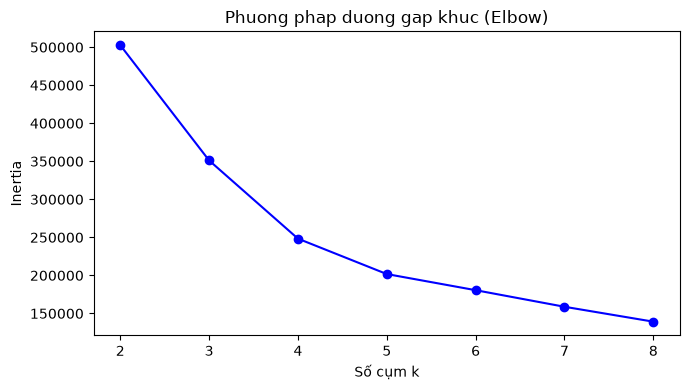

In [3]:
print('QUÉT SỐ CỤM k TRÊN TOÀN BỘ %s PHIEN' % f'{len(valid):,}')
Z = StandardScaler().fit_transform(valid[FEAT_3].to_numpy())
inertia = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
    lab = km.labels_; inertia[k] = km.inertia_
    idx = ms if len(Z) > N_SIL else np.arange(len(Z))
    print('  k=%d inertia=%9.0f sil=%.3f db=%.3f ch=%.0f sizes=%s'
          % (k, km.inertia_, silhouette_score(Z[idx], lab[idx]),
             davies_bouldin_score(Z[idx], lab[idx]),
             calinski_harabasz_score(Z[idx], lab[idx]),
             sorted(np.bincount(lab).tolist(), reverse=True)))
print('\nsố inertia theo k (tỷ lệ giảm):')
for k in range(2, 8):
    print('  k=%d -> k=%d : -%.1f%%' % (k, k + 1, 100 * (1 - inertia[k + 1] / inertia[k])))

plt.figure(figsize=(7, 4))
plt.plot(list(inertia), list(inertia.values()), 'bo-')
plt.xticks(list(inertia)); plt.xlabel('Số cụm k'); plt.ylabel('Inertia')
plt.title('Phuong phap duong gap khuc (Elbow)'); plt.tight_layout(); plt.show()


### DBSCAN: lưới tham số và độ ổn định


In [4]:
print('DBSCAN TRÊN MẪU %s PHIÊN (vì đường bộ xã kiểu O(n^2) không chạy được trên toàn bộ)'
      % f'{N_SIL:,}')
Zs = StandardScaler().fit_transform(valid[FEAT_3].to_numpy())[ms]
res = []
for eps, mp in itertools.product([0.5, 0.6, 0.7, 0.8, 0.9, 1.0], [10, 20, 50]):
    lab = DBSCAN(eps=eps, min_samples=mp).fit(Zs).labels_
    nc = len(set(lab)) - (-1 in set(lab))
    noise = 100 * (lab == -1).mean()
    res.append((eps, mp, nc, noise))
    print('  eps=%.1f min_samples=%2d -> số cụm=%d, tỷ lệ nhiễu=%.1f%%'
          % (eps, mp, nc, noise))
print('  tóm tắt: số cụm %d-%d, nhiễu %.1f%%-%.1f%%'
      % (min(r[2] for r in res), max(r[2] for r in res),
         min(r[3] for r in res), max(r[3] for r in res)))
print('  số tổ hợp trả về đúng 1 cụm: %d/18' % sum(r[2] == 1 for r in res))
print('  số tổ hợp trả về 2 cụm    : %d/18' % sum(r[2] == 2 for r in res))
print('  số tổ hợp trả về 3 cụm    : %d/18' % sum(r[2] == 3 for r in res))
print('  số tổ hợp trả về 4 cụm    : %d/18' % sum(r[2] == 4 for r in res))
print('  tổ hợp cho 4 cụm: %s' % [(r[0], r[1], round(r[3], 1)) for r in res if r[2] == 4])

# đối chiếu: DBSCAN cho 4 cụm có ổn định không, bằng cách chạy lại trên mẫu khác
print('\nKIỂM TRA ĐỘ ỔN ĐỊNH CỦA DBSCAN 4 CỤM TRÊN MẪU KHÁC NHAU:')
for seed in [0, 1, 2, 7, 42]:
    m2 = np.random.default_rng(seed).choice(len(valid), N_SIL, replace=False)
    Z2 = StandardScaler().fit_transform(valid[FEAT_3].to_numpy())[m2]
    lab = DBSCAN(eps=0.5, min_samples=10).fit(Z2).labels_
    nc = len(set(lab)) - (-1 in set(lab))
    print('  seed=%2d (eps=0.5 min_samples=10) -> số cụm=%d, nhiễu=%.1f%%'
          % (seed, nc, 100 * (lab == -1).mean()))


DBSCAN TRÊN MẪU 10,000 PHIÊN (vì đường bộ xã kiểu O(n^2) không chạy được trên toàn bộ)


  eps=0.5 min_samples=10 -> số cụm=4, tỷ lệ nhiễu=2.5%


  eps=0.5 min_samples=20 -> số cụm=1, tỷ lệ nhiễu=3.9%


  eps=0.5 min_samples=50 -> số cụm=1, tỷ lệ nhiễu=5.4%


  eps=0.6 min_samples=10 -> số cụm=2, tỷ lệ nhiễu=1.6%


...

  seed= 0 (eps=0.5 min_samples=10) -> số cụm=4, nhiễu=2.5%


  seed= 1 (eps=0.5 min_samples=10) -> số cụm=2, nhiễu=2.6%


  seed= 2 (eps=0.5 min_samples=10) -> số cụm=2, nhiễu=2.9%


  seed= 7 (eps=0.5 min_samples=10) -> số cụm=5, nhiễu=2.5%


  seed=42 (eps=0.5 min_samples=10) -> số cụm=2, nhiễu=2.9%


### Mô hình chọn (K-Means, k = 4) và hồ sơ cụm


In [5]:
K = 4
scaler = StandardScaler().fit(valid[FEAT_3].to_numpy())
Z = scaler.transform(valid[FEAT_3].to_numpy())
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
valid['cluster'] = km.labels_

prof = valid.groupby('cluster').agg(
    so_phien=('cluster', 'size'),
    ti_le=('cluster', lambda s: 100 * len(s) / len(valid)),
    ti_le_thoi_gian=('total_s', lambda s: 100 * s.sum() / valid['total_s'].sum()),
    tg_sac=('charging_h', 'mean'), tg_sac_trung_vi=('charging_h', 'median'),
    tg_nhan_roi=('idle_h', 'mean'), tg_nhan_roi_trung_vi=('idle_h', 'median'),
    idle_ratio=('idle_ratio', 'mean'), nang_luong=('kWh', 'mean'),
    nang_luong_trung_vi=('kWh', 'median'),
    gio_den=('hour', 'mean'), gio_den_trung_vi=('hour', 'median'),
    phien_idle_gt3h=('idle_h', lambda s: 100 * (s > 3).mean())).round(3)
print('HỒ SƠ %d CỤM (toàn bộ %s phiên):' % (K, f'{len(valid):,}'))
print(prof.to_string())

print('\ntỷ trọng tổng thời gian kết nối của mạng:')
print((prof['ti_le_thoi_gian'].round(2)).to_string())

print('\nphân bố giờ đến theo cụm (phân vị 10 / 50 / 90):')
print(valid.groupby('cluster')['hour'].describe(
    percentiles=[.1, .5, .9]).round(1)[['count', 'mean', '10%', '50%', '90%']].to_string())

print('\nphân bố theo năm (tỷ trọng trong từng cụm):')
print(pd.crosstab(valid['cluster'], valid['yr'], normalize='index').round(3).to_string())

print('\ntỷ lệ phiên có idle_ratio > 0,5 theo năm:')
print(valid.assign(hi=valid.idle_ratio > .5).groupby('yr')['hi'].mean().mul(100).round(2).to_string())


HỒ SƠ 4 CỤM (toàn bộ 259,206 phiên):
         so_phien   ti_le  ti_le_thoi_gian  tg_sac  tg_sac_trung_vi  tg_nhan_roi  tg_nhan_roi_trung_vi  idle_ratio  nang_luong  nang_luong_trung_vi  gio_den  gio_den_trung_vi  phien_idle_gt3h
cluster                                                                                                                                                                                        
0            5758   2.221            7.083   6.990            6.296        0.956                 0.025       0.092      38.370               35.211   14.070            13.767           12.331
1           91074  35.136           46.241   2.968            2.862        0.306                 0.008       0.073      13.060               12.264   12.622            12.167            1.038
2          155462  59.976           34.988   1.187            1.196        0.264                 0.006       0.117       4.569                4.562   13.947            13.867            0.807
3  

### Kiểm định độ ổn định: chia đôi và theo giai đoạn


In [6]:
rng = np.random.default_rng(1)
idx = rng.permutation(len(valid))
half = valid.iloc[idx[:len(valid) // 2]].copy()
k1 = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(
    StandardScaler().fit_transform(half[FEAT_3].to_numpy()))
half['h'] = k1.labels_
print('ĐỘ ỔN ĐỊNH: huấn luyện trên 1/2 dữ liệu (%d phien)' % len(half))
print(half.groupby('h')[FEAT_3 + ['idle_ratio']].mean().round(3).to_string())
print(half.groupby('h').size().to_string())

print('\nĐỘ ỔN ĐỊNH THEO CỬA SỔ: k = 4 riêng cho từng giai đoạn')
for a, b in [(2011, 2016), (2017, 2017), (2018, 2018), (2019, 2019), (2020, 2020)]:
    w = valid[(valid.yr >= a) & (valid.yr <= b)]
    Zw = StandardScaler().fit_transform(w[FEAT_3].to_numpy())
    lab = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zw).labels_
    p = w.assign(c=lab).groupby('c').agg(n=('c', 'size'), sac=('charging_h', 'mean'),
                                         roi=('idle_h', 'mean'), r=('idle_ratio', 'mean'),
                                         en=('kWh', 'mean'), gio=('hour', 'median')).round(2).sort_values('roi')
    print(' %d-%d (%s phiên): ' % (a, b, f'{len(w):,}'), ' | '.join(
        'roi %.2fh/r %.2f/%.1f kWh (%.0f%%)' % (r.roi, r.r, r.en, 100 * r.n / len(w))
        for _, r in p.iterrows()))


ĐỘ ỔN ĐỊNH: huấn luyện trên 1/2 dữ liệu (129603 phien)
   charging_h  idle_h     kWh  idle_ratio
h                                        
0       6.904   0.908  38.084       0.089
1       1.186   0.262   4.569       0.116
2       2.968   0.310  13.070       0.074
3       3.367   7.699  13.716       0.684
h
0     2907
1    77686
2    45543
3     3467

ĐỘ ỔN ĐỊNH THEO CỬA SỔ: k = 4 riêng cho từng giai đoạn


 2011-2016 (99,725 phiên):  roi 0.30h/r 0.13/4.1 kWh (56%) | roi 0.38h/r 0.09/11.9 kWh (39%) | roi 1.44h/r 0.13/41.1 kWh (1%) | roi 7.34h/r 0.68/13.2 kWh (4%)


 2017-2017 (48,977 phiên):  roi 0.30h/r 0.13/4.6 kWh (57%) | roi 0.32h/r 0.08/12.9 kWh (37%) | roi 1.38h/r 0.13/37.2 kWh (2%) | roi 7.64h/r 0.69/13.3 kWh (3%)


 2018-2018 (42,719 phiên):  roi 0.25h/r 0.06/13.2 kWh (34%) | roi 0.26h/r 0.11/4.8 kWh (63%) | roi 0.78h/r 0.08/39.5 kWh (2%) | roi 7.83h/r 0.68/16.1 kWh (1%)


 2019-2019 (47,690 phiên):  roi 0.22h/r 0.10/5.0 kWh (65%) | roi 0.32h/r 0.06/14.7 kWh (32%) | roi 1.36h/r 0.11/38.0 kWh (3%) | roi 112.49h/r 0.99/3.6 kWh (0%)


 2020-2020 (20,092 phiên):  roi 0.16h/r 0.08/4.8 kWh (64%) | roi 0.23h/r 0.05/15.6 kWh (30%) | roi 0.46h/r 0.05/37.2 kWh (5%) | roi 9.69h/r 0.67/22.9 kWh (1%)
